## Modelling Objectives and Approach

The aim of this modelling stage is to investigate whether machine learning models can assist in the allocation of targeted academic interventions by identifying students at risk of poor academic outcomes early in the school year. Two separate modelling tasks are considered:

1. **Non-completion classification:** Predicting the likelihood of a student receiving G3 = 0, using the full dataset.
2. **Final-grade prediction:** Predicting G3 among students who complete the course, excluding those with G3 = 0.

For each task, two feature sets are prepared: one containing only socio-environmental characteristics and another incorporating first-period grades (G1). This allows the predictive value of socio-environmental factors to be assessed independently and compared with models that include early academic performance.

Second-period grades (G2) are excluded throughout, as at-risk students should be identified as early in the academic year as practically possible. Furthermore, the strong correlation between G2 and G3 would likely lead to trivial predictions, offering little insight into the value of other predictors.

The following approach is used for both modelling tasks:

1. **Data preparation:** The dataset is divided into training (80%) and test (20%) sets. A reusable preprocessing pipeline applies the appropriate feature transformations and scaling for each task and feature set. Preprocessing is fitted on the training data and then applied to the test data to prevent data leakage.
2. **Baseline evaluation:** Simple baseline models are established to provide benchmarks for assessing whether more sophisticated approaches offer meaningful improvements.
3. **Model development:** Several algorithms are compared using cross-validation, followed by feature engineering, selection and hyperparameter tuning where appropriate.
4. **Final evaluation:** Selected models are assessed on the withheld test sets, with results interpreted in the context of their practical suitability for allocating targeted academic interventions.

### Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from preprocessing_utils import full_preprocessing_pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    cross_val_predict, GridSearchCV
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    log_loss, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, classification_report
)

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Data Loading and Target Definition

The raw student dataset is loaded and a binary target, **is_non_completer**, is created to identify students with no recorded final grade (G3 = 0).

In [2]:
path = os.path.join("..", "data", "raw", "Math-Students.csv")

df = pd.read_csv(path)

In [3]:
df_risk = df.copy()
df_risk["is_non_completer"] = (df_risk["G3"] == 0).astype(int)

### Train-Test Split and Preprocessing

The target variable (**is_non_completer**) is separated from the predictors and the data is split into training and test sets using stratification to preserve the proportion of non-completers.

The preprocessing pipeline is then applied to create two feature sets:

- **Socio-Environmental:** Excludes G1 and is used initially to explore feature importance and guide further feature engineering and selection.
- **Full:** Includes G1 alongside the socio-environmental features. Feature engineering and selection decisions from the socio-environmental analysis are later applied to this dataset for full risk modelling.

Preprocessing is fitted using the training data and then applied to the test data to prevent data leakage.

In [4]:
y = df_risk["is_non_completer"]
X_raw = df_risk.drop(columns=["is_non_completer"])

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

X_train_env, env_scaler = full_preprocessing_pipeline(X_train_raw, model_type="risk", include_g1=False)

X_test_env = full_preprocessing_pipeline(X_test_raw, model_type="risk", include_g1=False, scaler=env_scaler)

X_train_G1, G1_scaler = full_preprocessing_pipeline(X_train_raw, model_type="risk")

X_test_G1 = full_preprocessing_pipeline(X_test_raw, model_type="risk", scaler=G1_scaler)

print(f"Training set non-completion rate: {y_train.mean():.2%}")

Training set non-completion rate: 9.40%


### Model Evaluation

Four metrics are used to evaluate risk model performance:

- **Log Loss:** Measures the quality of predicted probabilities, with larger penalties for confident incorrect predictions. This is the primary metric used for model comparison and hyperparameter tuning.
- **Brier Score:** Measures the overall error of predicted probabilities, providing an additional check on probability quality.
- **ROC-AUC:** Measures how well the model distinguishes completers from non-completers across different thresholds.
- **Average Precision:** Summarises the precision-recall trade-off and is particularly useful given the class imbalance.


Lower values are better for **Log Loss** and **Brier Score**, whilst higher values are better for **ROC-AUC** and **Average Precision**.

In [5]:
def evaluate_risk_model(model_name, y_true, y_probs):
   
    ll   = log_loss(y_true, y_probs)
    bs   = brier_score_loss(y_true, y_probs)
    roc  = roc_auc_score(y_true, y_probs)
    ap   = average_precision_score(y_true, y_probs)
    
    metrics = {
        "Model": model_name,
        "Log Loss": round(ll, 2),
        "Brier": round(bs, 2),
        "ROC-AUC": round(roc, 2),
        "Avg Precision": round(ap, 2)
    }
    
    return metrics

all_results = []

### Naive Baseline

A naive baseline assigns every student the training-set non-completion rate as their predicted probability. This provides a reference point for determining whether subsequent models learn useful predictive information from the available features.

In [6]:
baseline_results = []

avg_non_completion_rate = y_train.mean() 
naive_probs = np.full(len(y_train), avg_non_completion_rate)

Naive_baseline_results = evaluate_risk_model("Naive Baseline", y_train, naive_probs)
baseline_results.append(Naive_baseline_results)
all_results.append(Naive_baseline_results)

display(pd.DataFrame([Naive_baseline_results]))

,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Naive Baseline,0.31,0.09,0.5,0.09


The naive baseline assigns every student a non-completion probability of approximately **9.4%**, resulting in a Log Loss of 0.31 and Brier Score of 0.09. Since the model does not distinguish between students, the ROC-AUC is 0.50 and Average Precision is approximately equal to the non-completion rate (0.09).

These results provide a baseline against which subsequent risk models can be compared.

### Initial Model Comparison

Before exploring feature importance and feature engineering, three baseline models are evaluated using the full training dataset with G1 included: **Logistic Regression**, **Random Forest**, and **XGBoost**. Class weighting is applied to account for the relatively small proportion of non-completers.

Predictions are generated using 5-fold cross-validation, allowing the initial models to be compared without using the test set.

In [7]:
log_reg_base = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
rfc_base = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42)
xgb_base = XGBClassifier(scale_pos_weight=10, random_state=42, eval_metric="logloss")

models = [
    ("Logistic Regression Baseline", log_reg_base), 
    ("Random Forest Baseline", rfc_base), 
    ("XGBoost Baseline", xgb_base)
]

for name, model in models:
    cv_probs = cross_val_predict(
        model, X_train_G1, y_train, 
        cv=5, method="predict_proba"
    )[:, 1]
    
    metrics = evaluate_risk_model(name, y_train, cv_probs)
    baseline_results.append(metrics)
    all_results.append(metrics)
    
baseline = pd.DataFrame(baseline_results)
display(baseline)

,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Naive Baseline,0.31,0.09,0.50,0.09
1,Logistic Regression Baseline,0.42,0.13,0.81,0.34
2,Random Forest Baseline,0.25,0.08,0.82,0.29
3,XGBoost Baseline,0.35,0.09,0.83,0.33


Whilst Logistic Regression and XGBoost improve substantially over the naive baseline in their ability to identify higher-risk students, their Log Loss scores are worse. Random Forest is the only model to improve on the naive baseline across all four metrics and hence provides the strongest starting point for further model development.

### Socio-Environmental Feature Exploration

As Random Forest provides the strongest performance in the initial model comparison, it is used to explore the predictive importance of the socio-environmental features independently of G1.

A class-weighted Random Forest is evaluated using 5-fold cross-validation, accounting for the relatively small proportion of non-completers whilst providing an initial estimate of performance.

In [8]:
engineering_results = []

rfc_env_initial = RandomForestClassifier(
    n_estimators=100, 
    max_depth=5, 
    class_weight="balanced", 
    random_state=42
)

cv_probs = cross_val_predict(
    rfc_env_initial, X_train_env, y_train, 
    cv=5, method="predict_proba"
)[:, 1]


rfc_initial_metrics = evaluate_risk_model("Initial Socio-Env RF (CV)", y_train, cv_probs)
engineering_results.append(rfc_initial_metrics)

display(pd.DataFrame([rfc_initial_metrics]))

,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Initial Socio-Env RF (CV),0.37,0.11,0.7,0.22


The socio-environmental model shows useful predictive signal without G1, achieving a ROC-AUC of 0.70 and Average Precision of 0.22, compared with baseline values of 0.50 and approximately 0.09 respectively. However, its Log Loss of 0.37 remains worse than the naive baseline (0.31), indicating that the predicted probabilities still require improvement.

### Initial Feature Importance

The Random Forest is fitted to the full socio-environmental training set to examine Gini feature importance. These rankings are used as an exploratory guide to identify potentially informative relationships and motivate subsequent feature engineering.

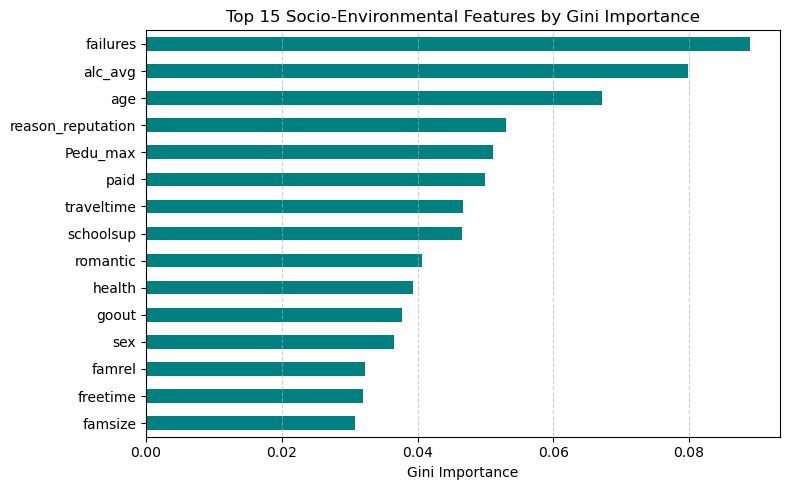

In [9]:
rfc_env_initial.fit(X_train_env, y_train)

importances = pd.Series(
    rfc_env_initial.feature_importances_, 
    index=X_train_env.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importances.head(15).plot(kind="barh", color="teal").invert_yaxis()
plt.title("Top 15 Socio-Environmental Features by Gini Importance")
plt.xlabel("Gini Importance")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

**Previous failures** show the highest importance, followed by **average alcohol consumption** (alc_avg) and **age**. Several academic and behavioural features also rank highly, suggesting that non-completion risk may depend on combinations of these factors rather than any single characteristic.

Four interaction features are therefore explored:

- **Support Gap:** combines previous failures with the absence of school support.
- **Social Distraction:** combines frequent socialising with low study time.
- **Lifestyle Risk:** combines age with alcohol consumption.
- **Health Burden:** combines high alcohol consumption with poor reported health.

### Interaction Feature Engineering

The proposed interactions combine features that may jointly capture patterns associated with non-completion. Since all variables are scaled to the range [0, 1], multiplicative interactions are used to assign higher values where both risk factors are present.

In [10]:
def inject_engineered_features(df):
    X = df.copy()
    
    X["support_gap_engineered"] = X["failures"] * (1 - X["schoolsup"])

    X["social_distraction_engineered"] = X["goout"] * (1 - X["studytime"])

    X["lifestyle_risk_engineered"] = X["age"] * X["alc_avg"]

    X["health_burden_engineered"] = X["alc_avg"] * (1 - X["health"])
    
    return X

X_train_env_engineered = inject_engineered_features(X_train_env)
X_test_env_engineered = inject_engineered_features(X_test_env)

### Evaluation of Engineered Features

The interaction features are added to the socio-environmental dataset and the Random Forest is re-evaluated using the same cross-validation procedure. The model is then fitted to the full training set to examine how the additional features affect the importance ranking.

,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Engineered Socio-Env RF (CV),0.37,0.1,0.69,0.21


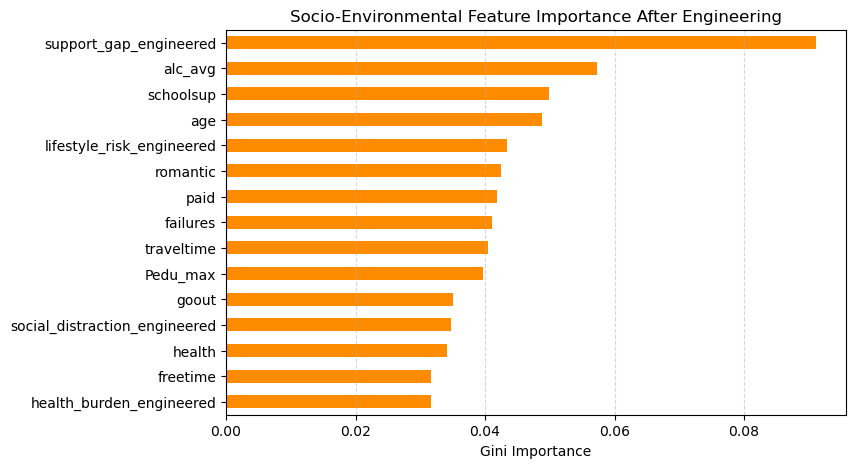

In [11]:
rfc_engineered_features = RandomForestClassifier(
    n_estimators=100, 
    max_depth=5, 
    class_weight="balanced", 
    random_state=42
)

cv_probs = cross_val_predict(
    rfc_engineered_features, X_train_env_engineered, y_train, 
    cv=5, method="predict_proba"
)[:, 1]


rfc_engineered_metrics = evaluate_risk_model("Engineered Socio-Env RF (CV)", y_train, cv_probs)
engineering_results.append(rfc_engineered_metrics)

display(pd.DataFrame([rfc_engineered_metrics]))


rfc_engineered_features.fit(X_train_env_engineered, y_train)


importances_eng = pd.Series(
    rfc_engineered_features.feature_importances_, 
    index=X_train_env_engineered.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importances_eng.head(15).plot(kind='barh', color="darkorange").invert_yaxis()
plt.title("Socio-Environmental Feature Importance After Engineering")
plt.xlabel("Gini Importance")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

The engineered features alter the importance ranking substantially, with **Support Gap** becoming the highest-ranked feature and Lifestyle Risk ranked fifth. However, this does not translate into improved cross-validated performance: Log Loss remains at 0.37, whilst ROC-AUC and Average Precision decrease slightly from 0.70 to 0.69 and 0.22 to 0.21 respectively.

The engineered features therefore offer no clear improvement in Random Forest performance. However, they provide explicit representations of potentially useful interactions and are retained as candidate features for subsequent model development, particularly for models such as Logistic Regression that cannot learn interactions implicitly.

### Feature Selection

The 15 highest-ranked features from the extended socio-environmental feature set are retained for subsequent modelling, whilst the remaining features are dropped to reduce dimensionality and remove less informative predictors.

It is important to note, however, that Gini importance is specific to the Random Forest, so the ranking may not reflect the relative importance of these features for other models. A simplified approach is used here, with the same reduced feature set applied consistently across each of the candidate models. A more thorough investigation could instead perform feature selection separately for each model.

In [12]:
features_to_keep = importances_eng.head(15).index.tolist()

X_train_env_final = X_train_env_engineered[features_to_keep]
X_test_env_final = X_test_env_engineered[features_to_keep]


X_train_G1_engineered = inject_engineered_features(X_train_G1)
X_test_G1_engineered = inject_engineered_features(X_test_G1)

X_train_G1_final = X_train_G1_engineered[features_to_keep + ["G1"]]
X_test_G1_final = X_test_G1_engineered[features_to_keep + ["G1"]]

print(f"Environmental Model: {X_train_env_final.shape[1]} features")
print(f"Integrated Model: {X_train_G1_final.shape[1]} features")

Environmental Model: 15 features
Integrated Model: 16 features


The selected socio-environmental features are also combined with G1 to create the full risk-modelling dataset.

### Contribution of Early Academic Performance

To assess the influence of feature selection and the additional predictive value of G1, the Random Forest is evaluated first using the selected socio-environmental features alone, and then with G1 included. The latter feature set will be referred to as the **selected full set**.

In [13]:
rfc_env = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight="balanced", random_state=42)
rfc_g1  = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight="balanced", random_state=42)

rfc_env.fit(X_train_env_final, y_train)

rfc_g1.fit(X_train_G1_final, y_train)

cv_probs_env = cross_val_predict(
    rfc_env, X_train_env_final, y_train, 
    cv=5, method="predict_proba"
)[:, 1]

rfc_env_metrics = evaluate_risk_model("Selected Socio-Env RF (CV)", y_train, cv_probs_env)
engineering_results.append(rfc_env_metrics)

cv_probs_g1 = cross_val_predict(
    rfc_g1, X_train_G1_final, y_train, 
    cv=5, method="predict_proba"
)[:, 1]

rfc_g1_metrics = evaluate_risk_model("Selected Socio-Env + G1 RF (CV)", y_train, cv_probs_g1)
engineering_results.append(rfc_g1_metrics)

engineering = pd.DataFrame(engineering_results)
display(engineering)


,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Initial Socio-Env RF (CV),0.37,0.11,0.70,0.22
1,Engineered Socio-Env RF (CV),0.37,0.10,0.69,0.21
2,Selected Socio-Env RF (CV),0.36,0.10,0.72,0.28
3,Selected Socio-Env + G1 RF (CV),0.29,0.09,0.84,0.37


Reducing the socio-environmental model to the selected features produces a modest improvement, increasing ROC-AUC from 0.70 to 0.72 and Average Precision from 0.22 to 0.28, whilst Log Loss improves slightly from 0.37 to 0.36.

The addition of G1 produces a much larger improvement. Log Loss falls to 0.29, while ROC-AUC increases to 0.84 and Average Precision to 0.37. Early academic performance therefore provides substantial additional predictive information beyond the socio-environmental features alone.

### Feature Importance with G1


The Random Forest is fitted to the full training data using the **selected full set** to examine how the Gini importance ranking changes with G1 included.

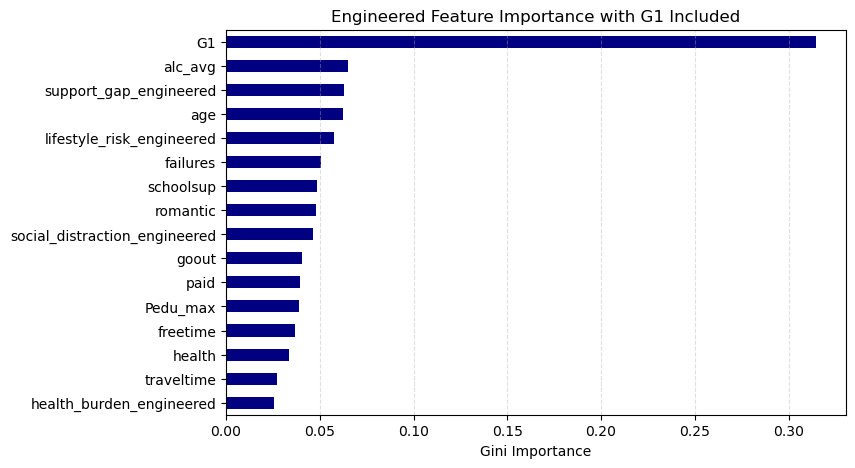

In [14]:
importances_g1 = pd.Series(rfc_g1.feature_importances_, index=X_train_G1_final.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
importances_g1.plot(kind="barh", color="navy").invert_yaxis()
plt.title("Engineered Feature Importance with G1 Included")
plt.xlabel("Gini Importance")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.show()

Once included, **G1** becomes by far the most important feature, clearly dominating over any individual socio-environmental predictor. Nevertheless, the remaining features continue to contribute to the model, with **alcohol consumption, support gap, age and previous failures** providing the strongest additional signals.

This highlights a clear distinction between the two modelling settings: socio-environmental features provide moderately useful early indications of non-completion risk, but predictive performance improves considerably once a student's G1 grade becomes available.

### Initial Model Comparison

The **selected full feature set**, comprising of the 15 highest ranked socio-environmental features and G1, is used to compare Logistic Regression, Random Forest and XGBoost.

The three models are evaluated using 5-fold cross-validation and their existing hyperparameter configurations to establish their initial performance before tuning. Log Loss remains the primary evaluation metric, alongside the Brier score, ROC-AUC and Average Precision.

In [15]:
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
rfc_final = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42)
xgb_final = XGBClassifier(scale_pos_weight=10, random_state=42, eval_metric="logloss")

models = [
    ("Logistic Regression", log_reg), 
    ("Random Forest", rfc_final), 
    ("XGBoost", xgb_final)
]

untuned_results = []

for name, model in models:
    cv_probs = cross_val_predict(
        model, X_train_G1_final, y_train, 
        cv=5, method="predict_proba"
    )[:, 1]
    
    metrics = evaluate_risk_model(f"Final {name} Untuned", y_train, cv_probs)
    untuned_results.append(metrics)
    all_results.append(metrics)
    
untuned = pd.DataFrame(untuned_results)
display(untuned)

,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Final Logistic Regression Untuned,0.45,0.15,0.86,0.42
1,Final Random Forest Untuned,0.24,0.07,0.83,0.34
2,Final XGBoost Untuned,0.39,0.10,0.80,0.37


The Random Forest achieves the lowest Log Loss (0.24) and Brier score (0.07), suggesting that it produces the most accurate probability estimates at this stage.

Logistic Regression continues to perform poorly in terms of probability accuracy, with a Log Loss of 0.45, but achieves the highest ROC-AUC (0.86) and Average Precision (0.42). This suggests that it distinguishes between completers and non-completers relatively well, despite its poorer probability estimates.

These results provide a starting point for hyperparameter tuning.

### Hyperparameter Tuning

Each candidate model is tuned using GridSearchCV, with 5-fold cross-validation and negative Log Loss as the scoring criterion. This prioritises the quality of predicted probabilities, heavily penalising confident incorrect predictions.

The search explores model-specific parameters, including regularisation strength and type for Logistic Regression, tree complexity for Random Forest, and learning rate, tree depth and class weighting for XGBoost.

The best-performing configuration for each model is then evaluated using out-of-fold predictions to compare performance across the same metrics.

In [16]:
param_log = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"],
    "class_weight": [None, "balanced"]
}

param_rfc = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 8],
    "min_samples_split": [2, 5, 10],
    "class_weight": ["balanced", "balanced_subsample"]
}

param_xgb = {
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5],
    "n_estimators": [100, 200],
    "subsample": [0.8, 1.0],
    "scale_pos_weight": [8, 10, 12] 
}

tuned_results = []

def tune_model(model, params, X, y, name):
    grid = GridSearchCV(
        model, params, 
        cv=5, 
        scoring="neg_log_loss", 
        n_jobs=-1
    )
    grid.fit(X, y)
    
    best_model = grid.best_estimator_
    best_params = grid.best_params_
    
    cv_probs = cross_val_predict(
        best_model, X, y, 
        cv=5, method="predict_proba"
    )[:, 1]
    
    metrics = evaluate_risk_model(f"Final {name} Tuned", y, cv_probs)
    all_results.append(metrics)
    tuned_results.append(metrics)
    
    return best_model, metrics, best_params

best_log, metrics_log, params_log = tune_model(
    LogisticRegression(random_state=42), param_log, X_train_G1_final, y_train, "Logistic Regression"
)
best_rfc, metrics_rfc, params_rfc = tune_model(
    RandomForestClassifier(random_state=42), param_rfc, X_train_G1_final, y_train, "Random Forest"
)
best_xgb, metrics_xgb, params_xgb = tune_model(
    XGBClassifier(random_state=42, eval_metric="logloss"), param_xgb, X_train_G1_final, y_train, "XGBoost"
)

full_tuned_results = pd.DataFrame(tuned_results)
display(full_tuned_results)

,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Final Logistic Regression Tuned,0.22,0.07,0.88,0.48
1,Final Random Forest Tuned,0.25,0.07,0.82,0.37
2,Final XGBoost Tuned,0.28,0.09,0.84,0.37


In [17]:
print("Best Logistic Regression parameters:")
print(params_log)

Best Logistic Regression parameters:
{'C': 1, 'class_weight': None, 'penalty': 'l1', 'solver': 'liblinear'}


Hyperparameter tuning produces a substantial improvement in Logistic Regression, **reducing Log Loss from 0.45 to 0.22**, increasing ROC-AUC from 0.86 to 0.88, and Average Precision from 0.42 to 0.48.

The selected configuration uses L1 regularisation (C = 1). L1 regularisation can shrink less informative coefficients to zero, helping to simplify the model.

In contrast, tuning produces little improvement for Random Forest and more modest results for XGBoost.  Logistic Regression now performs best across all four evaluation metrics, making it the strongest candidate for the final model.

### Predicting Non-Completion Without G1

Although the 'selected full' model demonstrates stronger performance, its reliance on G1 means that predictions cannot be made until first-period grades become available.

To investigate the potential for earlier identification, Logistic Regression is also tuned and evaluated using **only** the selected socio-environmental features, following the same procedure as the full model.

In [18]:
best_log_env, metrics_log_env, params_log_env = tune_model(
    LogisticRegression(random_state=42), param_log, X_train_env_final, y_train, "Logistic Regression Env"
)

display(pd.DataFrame([metrics_log_env]))

,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Final Logistic Regression Env Tuned,0.28,0.08,0.75,0.26


The resulting model achieves a Log Loss of 0.28 and ROC-AUC of 0.75. Although this represents an improvement over the baseline models, its predictive performance remains modest, especially compared with the full model incorporating G1.

It is concluded that socio-environmental features alone are insufficient for reliable identification of at-risk students. Whilst they provide some early indications of non-completion risk, the model is considerably more effective once G1 becomes available, making this the more appropriate stage for its practical application.

## Final Model Evaluation

The tuned Logistic Regression model is selected for final evaluation using the **selected full feature set**.

### Cross-Validated Probability Performance

Out-of-fold predictions from 5-fold cross-validation are used to assess performance on the training data, ensuring that each student is predicted by a model that was not fitted on their observation.

In addition to the usual four metrics, an ROC curve is plotted to visualise the trade-off between the true positive rate (recall) and false positive rate across different classification thresholds.

In [19]:
train_cv_probs = cross_val_predict(
    best_log,
    X_train_G1_final,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Final Tuned LogReg (Training Set),0.22,0.07,0.88,0.48


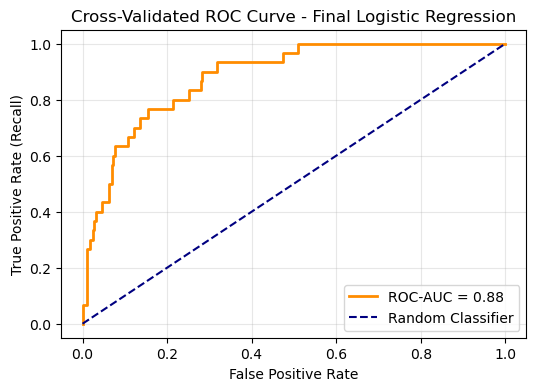

In [20]:
train_metrics = evaluate_risk_model("Final Tuned LogReg (Training Set)", y_train, train_cv_probs)

train_metrics_df = pd.DataFrame([train_metrics])
display(train_metrics_df)

fpr, tpr, _ = roc_curve(y_train, train_cv_probs)

plt.figure(figsize=(6, 4))

plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC-AUC = {train_metrics['ROC-AUC']:.2f}")
plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Cross-Validated ROC Curve - Final Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

The final model demonstrates promising cross-validated performance, although some limitations remain.

The ROC-AUC of 0.88 confirms strong overall discrimination, whilst the relatively low Log Loss (0.22) and Brier score (0.07) suggest reasonably accurate probability estimates. However, Average Precision reamains modest (0.48) highlighting the difficulty of identifying the relatively small number of non-completers without generating false positives.

The ROC curve sits well above the diagonal reference line, indicating that the model distinguishes between completers and non-completers considerably better than random classification. Its steep initial rise is encouraging, suggesting that a substantial proportion of non-completers can be identified whilst maintaining a relatively low false positive rate. Nevertheless, as reflected in the Average Precision score, a low false positive rate can still produce a substantial number of false positives when the positive class is rare.

Although these results demonstrate promising predictive performance, they do not establish how students should be classified in practice. A suitable classification threshold must therefore be selected, balancing the identification of at-risk students against the number of false positives.

### Classification Threshold Selection

The default classification threshold of 0.50 is not necessarily appropriate for this task, particularly given that non-completers account for only 9.4% of the dataset.

The model's intended purpose is to identify students who may benefit from additional academic support. In this context, **recall is particularly important**, as failing to identify an at-risk student could mean missing an opportunity for early intervention.

However, precision must also be considered. A threshold that flags too many students incorrectly could place unnecessary demands on limited support resources.

To examine this trade-off, thresholds between 0.10 and 0.50 are evaluated using the out-of-fold training predictions. Precision, recall and F1-score are calculated for the non-completer class, with F1 providing a summary of the balance between the two.

In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in np.arange(0.10, 0.51, 0.05):
    preds = (train_cv_probs >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, preds),
        "Recall": recall_score(y_train, preds),
        "F1": f1_score(y_train, preds)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Threshold,Precision,Recall,F1
0,0.10,0.250000,0.800000,0.380952
1,0.15,0.360656,0.733333,0.483516
2,0.20,0.441860,0.633333,0.520548
3,0.25,0.464286,0.433333,0.448276
4,0.30,0.642857,0.300000,0.409091
5,0.35,0.700000,0.233333,0.350000
6,0.40,0.625000,0.166667,0.263158
7,0.45,0.400000,0.066667,0.114286
8,0.50,0.500000,0.066667,0.117647


A threshold of **0.20** achieves the highest F1-score (0.52) among those evaluated, with precision of 0.44 and recall of 0.63.

Lower thresholds identify a greater proportion of non-completers but produce considerably more false positives. Conversely, increasing the threshold from 0.20 to 0.25 reduces recall from 0.63 to 0.43, whilst improving precision only marginally.

A threshold of 0.20 is therefore selected as a reasonable compromise between identifying students at risk and limiting unnecessary interventions.

### Cross-Validated Classification Performance

The selected threshold of 0.20 is applied to the out-of-fold training predictions to examine classification performance.

<Figure size 400x200 with 0 Axes>

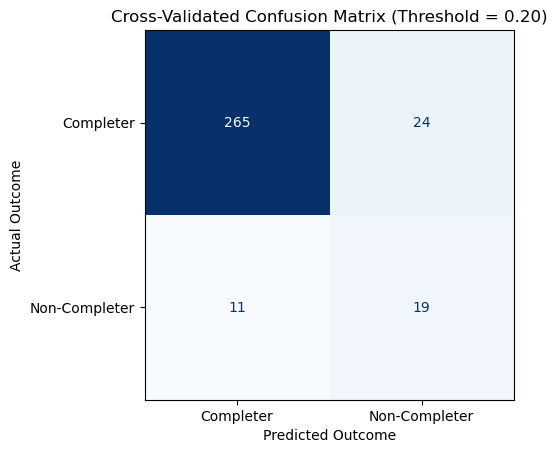

,precision,recall,f1-score,support
Completer,0.960145,0.916955,0.938053,289.0
Non-Completer,0.441860,0.633333,0.520548,30.0


In [22]:
threshold = 0.2
y_pred_thresholded = (train_cv_probs >= threshold).astype(int)

plt.figure(figsize=(4, 2))

cm = confusion_matrix(y_train, y_pred_thresholded)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Completer", "Non-Completer"])
disp.plot(cmap="Blues", colorbar=False)

plt.title(f"Cross-Validated Confusion Matrix (Threshold = {threshold:.2f})")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

train_report = classification_report(
    y_train, y_pred_thresholded, target_names=["Completer", "Non-Completer"], output_dict=True
)

train_report_df = pd.DataFrame(train_report).T
train_report_df = train_report_df.loc[["Completer", "Non-Completer"]]

display(train_report_df)

The model correctly identifies **19 of the 30 non-completers**, giving a recall of 63%. However, it also **incorrectly flags 24 completers**, resulting in precision of 44% for the non-completer class.

Whilst this precision is relatively modest, it is substantially higher than the underlying non-completion rate of approximately 9.4%. The model therefore identifies a group of students with considerably higher risk than the overall student population.

Nevertheless, 11 non-completers remain unidentified, highlighting an important limitation if the model were to be used to guide academic support. Its predictions would be most appropriate as an additional source of information, rather than as a standalone basis for intervention decisions.

## Final Evaluation on the Withheld Test Set

Following model development and threshold selection, the final Logistic Regression model is fitted to the complete training dataset and evaluated on the previously unseen test set, following the same evaluation procedure used for the training data.

The selected features, hyperparameters and classification threshold of 0.20 remain unchanged, providing an independent assessment of how well the model generalises beyond the data used for development.

In [23]:
best_log.fit(X_train_G1_final, y_train)

LogisticRegression(C=1, penalty='l1', random_state=42, solver='liblinear')

### Test Set Probability Performance

,Model,Log Loss,Brier,ROC-AUC,Avg Precision
0,Final Tuned LogReg (Test Set),0.23,0.07,0.88,0.48


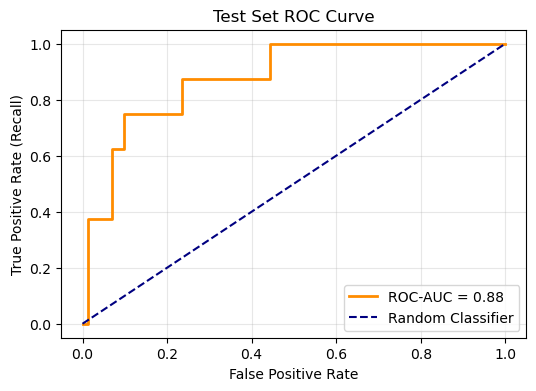

In [24]:
y_test_probs = best_log.predict_proba(X_test_G1_final)[:, 1]

test_metrics = evaluate_risk_model("Final Tuned LogReg (Test Set)", y_test, y_test_probs)

test_metrics_df = pd.DataFrame([test_metrics])
display(test_metrics_df)

fpr, tpr, _ = roc_curve(y_test, y_test_probs)

plt.figure(figsize=(6, 4))

plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC-AUC = {test_metrics['ROC-AUC']:.2f}")
plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Test Set ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

The model demonstrates promising performance on the unseen test data, with results closely aligned to those obtained from cross-validation. All four metrics remain essentially unchanged, and the test ROC curve closely resembles the cross-validated training curve.

These results suggest that the model's probability accuracy and ability to distinguish between completers and non-completers generalise well to unseen data from the same dataset.

### Test Set Classification Performance

The previously selected threshold of 0.20 is applied to the test predictions, with a confusion matrix and classification report used to assess the model's classification performance on unseen data.

<Figure size 400x200 with 0 Axes>

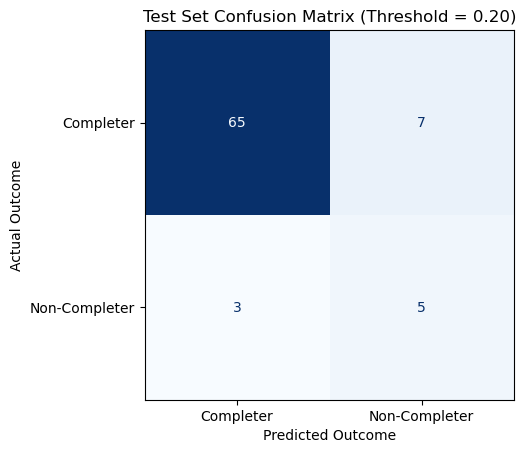

,precision,recall,f1-score,support
Completer,0.955882,0.902778,0.928571,72.0
Non-Completer,0.416667,0.625000,0.500000,8.0


In [25]:
y_test_pred_thresholded = (y_test_probs >= threshold).astype(int)

plt.figure(figsize=(4, 2))

cm = confusion_matrix(y_test, y_test_pred_thresholded)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Completer", "Non-Completer"])
disp.plot(cmap="Blues", colorbar=False)

plt.title(f"Test Set Confusion Matrix (Threshold = {threshold:.2f})")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

test_report = classification_report(y_test, y_test_pred_thresholded, target_names=["Completer", "Non-Completer"], output_dict=True)

test_report_df = pd.DataFrame(test_report).T
test_report_df = test_report_df.loc[["Completer", "Non-Completer"]]

display(test_report_df)

The model correctly identifies **5 of the 8 non-completers**, achieving a recall of 62.5%, whilst incorrectly flagging 7 completers, resulting in precision of 41.7%.

These results are consistent with the cross-validated training performance, where recall and precision were 63.3% and 44.2%, respectively. This suggests that the selected threshold of 0.20 maintains a similar precision-recall balance on unseen data.

However, with only eight non-completers in the test set, these estimates are sensitive to individual observations and should be interpreted cautiously.

### Investigating False Positives

Given that the proposed application of the model is to assist in selecting students for intervention, the fact that some completers are incorrectly flagged as non-completers is not strictly a failure, provided that these students still experienced academic difficulty. 

To investigate this, the final grades (G3) of **completers** in the withheld test set are compared according to whether they were flagged as high-risk by the model.

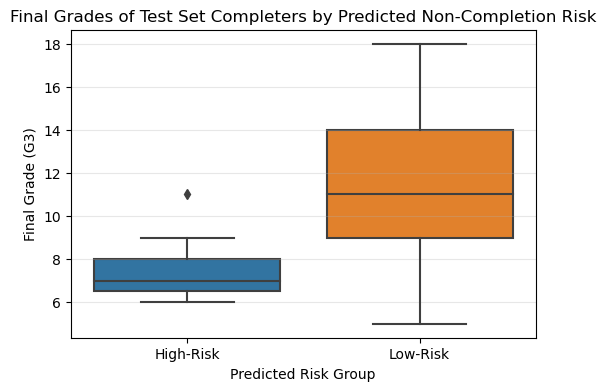

,count,mean,median
Risk Group,,,
High-Risk,7,7.571429,7.0
Low-Risk,65,11.569231,11.0


In [26]:
completers = pd.DataFrame({
    "G3": df.loc[X_test_G1_final.index, "G3"].to_numpy(),
    "Risk Group": np.where(y_test_pred_thresholded == 1, "High-Risk", "Low-Risk"),
    "Actual Outcome": np.asarray(y_test)
})

completers = completers[completers["Actual Outcome"] == 0]

plt.figure(figsize=(6, 4))

sns.boxplot(
    data=completers,
    x="Risk Group",
    y="G3",
    order=["High-Risk", "Low-Risk"]
)

plt.xlabel("Predicted Risk Group")
plt.ylabel("Final Grade (G3)")
plt.title("Final Grades of Test Set Completers by Predicted Non-Completion Risk")
plt.grid(axis="y", alpha=0.3)

plt.show()

display(completers.groupby("Risk Group")["G3"].agg(["count", "mean", "median"]))

Completers flagged as high-risk in the test data generally achieved considerably lower final grades, with a median G3 of approximately 7 compared with 11 for those not flagged.

This suggests that some false positives may still represent students experiencing academic difficulties, despite ultimately completing the course. However, the flagged group contains only seven students, and the strong relationship between G1 and G3 means this finding is not entirely unexpected.

Nevertheless, the results highlight an important distinction: predicting non-completion alone does not capture the full range of students who may benefit from academic support. In practice, the model would be considered alongside a complimentary performance model predicting final grades (G3), developed later in this notebook. Together, the two models could provide a more comprehensive assessment of academic risk to help inform intervention decisions.

### Discussion and Limitations

The final Logistic Regression model demonstrates promising predictive performance, with strong discrimination and consistent results across cross-validation and the unseen test set.

The analysis highlights the importance of timing when making predictions in practice. Whilst socio-environmental characteristics provide some early indications of non-completion risk, models trained on these characeristics alone perform insufficiently for worthwhile implementation. Incorporating G1, however, considerably improves predictive performance and, as such, predictive modelling is best implemented after first-period grades become available.

At the selected threshold of 0.20, the model identifies approximately 63% of non-completers, however over half of the students flagged as high-risk are completers. This trade-off may be acceptable for low-cost interventions, but would require further consideration where support resources are limited.

Several limitations should also be acknowledged. The dataset is small, with a low proportion of non-completers, making performance estimates sensitive to individual observations.

Furthermore, non-completion itself is not an ideal target variable when identifying students for intervention. Here, non-completion is inferred from a final grade of zero rather than verified withdrawal records. Whilst exploratory analysis found non-completion to be associated with indicators of academic difficulty and disengagement, some students may lack a final grade for unrelated reasons, such as illness or transferring schools. Such edge cases may be difficult for the model to predict given the small dataset and available features, and are arguably not even relevant to intervention allocation in the first place.

Ideally, non-completion should be verified against withdrawal records, and a more appropriate target variable defined that excludes cases not relevant to academic or pastoral intervention.

### Conclusion and Next Steps

Overall, the results suggest that the model could provide useful supplementary information for identifying students at risk of non-completion. Furthermore, the lower final grades observed among incorrectly flagged completers suggest that some of these predictions may still highlight students experiencing academic difficulties, even when they ultimately complete the course.

The next stage of this project will focus on predicting final grades (G3) among students who complete the course. Together, the two models could provide complementary assessments of non-completion risk and expected academic performance, potentially supporting more informed decisions about which students may benefit from additional support.

# Performance Model

### Predicting Final Academic Performance

Having examined the risk of non-completion, the next objective is to predict students' final grades (G3). This is a regression problem, where the aim is to estimate a continuous numerical outcome.

Students with **G3 = 0** (non-completers) are **excluded** from this analysis, allowing models to focus exclusively on academic performance among students with recorded non-zero final grades (completers).

In [27]:
df_perf = df[df["G3"] > 0].copy()

### Train-Test Split and Preprocessing

Following a similar approach to the risk analysis, two feature sets are prepared: one containing only socio-environmental characteristics, and another incorporating the first-period grade (G1). This allows assessment of how much predictive information is available from students' backgrounds and circumstances alone, and the extent to which including prior academic performance improves predictions.

The data is split into an 80% training set and a 20% test set, with five-fold cross-validation used for model development and comparison.

In [28]:
y_perf = df_perf["G3"]
X_perf_raw = df_perf.drop(columns=["G3"])

X_train_perf_raw, X_test_perf_raw, y_train_perf, y_test_perf = train_test_split(
    X_perf_raw, y_perf, test_size=0.2, random_state=42
)

X_train_perf_env, perf_env_scaler = full_preprocessing_pipeline(
    X_train_perf_raw, model_type="performance", include_g1=False
)
X_test_perf_env = full_preprocessing_pipeline(
    X_test_perf_raw, model_type="performance", include_g1=False, scaler=perf_env_scaler
)
X_train_perf_G1, perf_G1_scaler = full_preprocessing_pipeline(
    X_train_perf_raw, model_type="performance", include_g1=True
)
X_test_perf_G1 = full_preprocessing_pipeline(
    X_test_perf_raw, model_type="performance", include_g1=True, scaler=perf_G1_scaler
)

cv_perf = KFold(n_splits=5, shuffle=True, random_state=42)
print(f"Regression training observations: {len(y_train_perf)}")

Regression training observations: 288


### Evaluation Metrics

Model performance is assessed using three regression metrics:

- **Mean Absolute Error (MAE):** The average absolute difference between predicted and actual grades, expressed in grade points.
- **Root Mean Squared Error (RMSE):** Similar to MAE, but places greater emphasis on larger prediction errors.
- **R²:** Measures predictive performance relative to a constant prediction based on the mean grade. Higher values indicate better performance.

In [29]:
def evaluate_performance_model(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    metrics = {
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R²": round(r2, 2)
    }
    return metrics

all_results_perf = []

### Baseline Models

Two baseline approaches are established:

- **Naive baseline:** Predicts the mean final grade of the training observations.
- **G1 persistence baseline:** Assumes that each student's final grade will equal their first-period grade (G1).

These provide reference points for assessing whether more sophisticated models offer meaningful improvements in predictive accuracy.

In [30]:
baseline_results_perf = []

mean_grade = y_train_perf.mean()
naive_preds = cross_val_predict(
    __import__("sklearn.dummy", fromlist=["DummyRegressor"]).DummyRegressor(strategy="mean"),
    X_train_perf_env, y_train_perf, cv=cv_perf
)

naive_metrics = evaluate_performance_model("Naive Baseline", y_train_perf, naive_preds)
baseline_results_perf.append(naive_metrics)
all_results_perf.append(naive_metrics)

g1_train = df.loc[y_train_perf.index, "G1"].to_numpy()
g1_metrics = evaluate_performance_model("G1 Persistence Baseline", y_train_perf, g1_train)
baseline_results_perf.append(g1_metrics)
all_results_perf.append(g1_metrics)

display(pd.DataFrame(baseline_results_perf))

,Model,MAE,RMSE,R²
0,Naive Baseline,2.71,3.33,-0.01
1,G1 Persistence Baseline,1.16,1.50,0.80


The naive baseline performs poorly, with an MAE of 2.71 and an R² of approximately zero, in line with expectations.

In contrast, the G1 persistence baseline achieves an MAE of just **1.16** and an R² of **0.80**. This indicates that first-period performance is already a strong predictor of final grades, consistent with the strong positive correlation between G1 and G3 identified during exploratory analysis.

G1 persistence therefore provides a challenging benchmark for subsequent regression models, and any additional model complexity should be justified by meaningful improvements in predictive accuracy.

### Predicting Performance from Socio-Environmental Factors

Before incorporating G1, three regression algorithms are first evaluated using only socio-environmental features:

- **Linear Regression:** Establishes a simple linear relationship between student characteristics and final grades.
- **Random Forest:** Captures potentially non-linear relationships and interactions between predictors.
- **XGBoost:** Uses gradient-boosted decision trees to model more complex patterns.

Each model is evaluated using five-fold cross-validation with default or initial hyperparameters, without tuning. This provides an initial assessment of how accurately final grades can be predicted using only information available before first-period grades (G1) become available.

In [31]:
env_results_perf = []

lin_env = LinearRegression()
rf_env = RandomForestRegressor(n_estimators=100, random_state=42)
xgb_env = XGBRegressor(n_estimators=100, random_state=42, objective="reg:squarederror")

models = [
    ("Linear Regression Socio-Env", lin_env),
    ("Random Forest Socio-Env", rf_env),
    ("XGBoost Socio-Env", xgb_env)
]

for name, model in models:
    cv_preds = cross_val_predict(model, X_train_perf_env, y_train_perf, cv=cv_perf)
    metrics = evaluate_performance_model(name, y_train_perf, cv_preds)
    env_results_perf.append(metrics)
    all_results_perf.append(metrics)

display(pd.DataFrame(env_results_perf))

,Model,MAE,RMSE,R²
0,Linear Regression Socio-Env,2.45,3.06,0.15
1,Random Forest Socio-Env,2.39,2.99,0.18
2,XGBoost Socio-Env,2.41,3.05,0.15


The socio-environmental models achieve only modest improvements over the naive baseline, with MAEs ranging from 2.39 to 2.45 and R² values between 0.15 and 0.18. Random Forest performs slightly better than Linear Regression and XGBoost, but the differences are small. All three models perform substantially worse than G1 persistence, as expected.

These results suggest that socio-environmental characteristics contain some useful predictive information, but are insufficient on their own to meaningfully estimate final grades.

To investigate which characteristics contribute most strongly to these predictions, feature importance is examined using the Random Forest model.

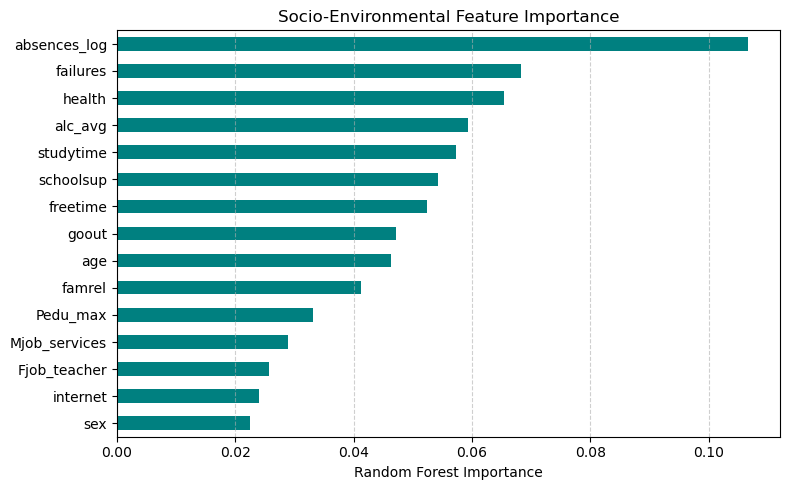

In [32]:
rf_env.fit(X_train_perf_env, y_train_perf)

importances = pd.Series(
    rf_env.feature_importances_, index=X_train_perf_env.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importances.head(15).plot(kind="barh", color="teal").invert_yaxis()
plt.title("Socio-Environmental Feature Importance")
plt.xlabel("Random Forest Importance")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

The Random Forest identifies **log-transformed absences** as the most important socio-environmental predictor, followed by previous failures and self-reported health. Average alcohol consumption, study time and additional school support also contribute relatively strongly to the model's predictions.

These findings suggest that attendance, previous academic difficulties and aspects of students' health and behaviour may contain useful information about final academic performance.

However, Random Forest feature importance does not indicate the direction of these relationships or establish causality. Furthermore, the relatively modest predictive performance of the socio-environmental models suggests that these characteristics alone cannot reliably explain differences in final grades.

### Feature Engineering

Several interaction features are introduced to capture relationships between student characteristics that may not be adequately represented by individual predictors:

- **Academic disengagement:** Combines higher absence levels with lower study time.
- **Support gap:** Combines previous academic failures with the absence of additional school support.
- **Lifestyle risk:** Combines age and average alcohol consumption.
- **Health burden:** Combines higher alcohol consumption with poorer self-reported health.

These features are constructed from the existing preprocessed variables. Random Forest is then used to compare predictive performance before and after feature engineering, and to reassess feature importance with the new variables included.

Although Random Forest can already capture non-linear relationships and interactions, the importance rankings provide an initial indication of whether the engineered features contain useful predictive information. Their potential value for other algorithms, particularly linear models, is explored in subsequent modelling.

In [33]:
def inject_perf_engineered_features(df):
    X = df.copy()

    X["academic_disengagement"] = X["absences_log"] * (1 - X["studytime"])
    X["support_gap_engineered"] = X["failures"] * (1 - X["schoolsup"])
    X["lifestyle_risk_engineered"] = X["age"] * X["alc_avg"]
    X["health_burden_engineered"] = X["alc_avg"] * (1 - X["health"])

    return X

X_train_perf_env_engineered = inject_perf_engineered_features(X_train_perf_env)
X_test_perf_env_engineered = inject_perf_engineered_features(X_test_perf_env)

,Model,MAE,RMSE,R²
0,Original Socio-Env RF,2.39,2.99,0.18
1,Engineered Socio-Env RF,2.40,3.01,0.17


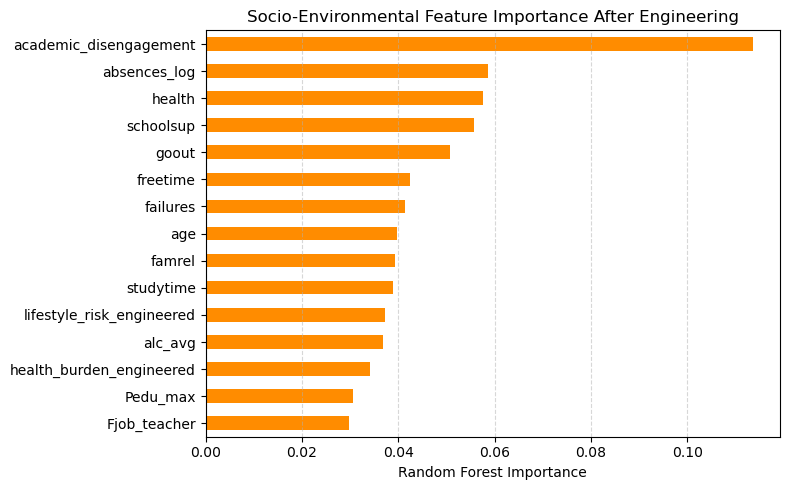

In [34]:
engineering_results_perf = []

cv_preds = cross_val_predict(rf_env, X_train_perf_env, y_train_perf, cv=cv_perf)
metrics = evaluate_performance_model("Original Socio-Env RF", y_train_perf, cv_preds)
engineering_results_perf.append(metrics)

cv_preds = cross_val_predict(rf_env, X_train_perf_env_engineered, y_train_perf, cv=cv_perf)
metrics = evaluate_performance_model("Engineered Socio-Env RF", y_train_perf, cv_preds)
engineering_results_perf.append(metrics)
all_results_perf.append(metrics)

display(pd.DataFrame(engineering_results_perf))

rf_env.fit(X_train_perf_env_engineered, y_train_perf)
importances_eng = pd.Series(
    rf_env.feature_importances_, index=X_train_perf_env_engineered.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importances_eng.head(15).plot(kind="barh", color="darkorange").invert_yaxis()
plt.title("Socio-Environmental Feature Importance After Engineering")
plt.xlabel("Random Forest Importance")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Feature engineering does not improve Random Forest performance. The engineered model achieves an MAE of 2.40 and an R² of 0.17, compared with 2.39 and 0.18 for the original model. This is not entirely unexpected, as Random Forest can already capture non-linear relationships and interactions between predictors.

Nevertheless, academic disengagement emerges as the most important feature, suggesting that the interaction between attendance and study time is useful to the fitted model, even if it does not improve overall predictive accuracy.

Feature importance is model-specific, and the usefulness of these engineered features may differ across models. They are therefore retained for subsequent modelling as explicitly representing these interactions may potentially benefit linear models that cannot otherwise capture them directly.

### Incorporating Prior Academic Performance (G1)

The next stage incorporates first-period grades (G1) alongside the socio-environmental and engineered features.

Linear Regression, Random Forest and XGBoost are evaluated using five-fold cross-validation with their initial hyperparameters. This allows direct comparison with the earlier socio-environmental models and provides an initial assessment of how substantially the inclusion of G1 improves predictive accuracy.

Random Forest feature importance is also reassessed to examine how the relative importances of socio-environmental and engineered features change once G1 is included.

,Model,MAE,RMSE,R²
0,Linear Regression + G1,1.20,1.48,0.80
1,Random Forest + G1,1.22,1.49,0.80
2,XGBoost + G1,1.32,1.68,0.74


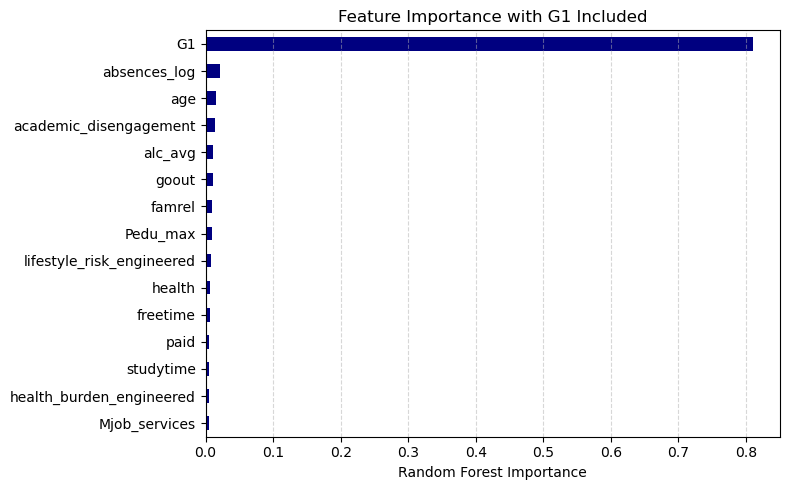

In [35]:
X_train_perf_G1_engineered = inject_perf_engineered_features(X_train_perf_G1)
X_test_perf_G1_engineered = inject_perf_engineered_features(X_test_perf_G1)

full_results_perf = []

lin_full = LinearRegression()
rf_full = RandomForestRegressor(n_estimators=100, random_state=42)
xgb_full = XGBRegressor(n_estimators=100, random_state=42, objective="reg:squarederror")

models = [
    ("Linear Regression + G1", lin_full),
    ("Random Forest + G1", rf_full),
    ("XGBoost + G1", xgb_full)
]

for name, model in models:
    cv_preds = cross_val_predict(model, X_train_perf_G1_engineered, y_train_perf, cv=cv_perf)
    metrics = evaluate_performance_model(name, y_train_perf, cv_preds)
    full_results_perf.append(metrics)
    all_results_perf.append(metrics)

display(pd.DataFrame(full_results_perf))

rf_full.fit(X_train_perf_G1_engineered, y_train_perf)

importances_g1 = pd.Series(
    rf_full.feature_importances_, index=X_train_perf_G1_engineered.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importances_g1.head(15).plot(kind="barh", color="navy").invert_yaxis()
plt.title("Feature Importance with G1 Included")
plt.xlabel("Random Forest Importance")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Including G1 produces a substantial improvement in predictive performance across all three models. Linear Regression and Random Forest achieve MAEs of 1.20 and 1.22 respectively, with both explaining approximately 80% of the variation in final grades. XGBoost performs slightly worse, with an MAE of 1.32 and an R² of 0.74.

The Random Forest feature-importance plot reinforces this finding, with G1 now accounting for the overwhelming majority of the model's total feature importance.

Despite these improvements, none of the initial models outperform the G1 persistence baseline, which achieved an MAE of 1.16. 

### Hyperparameter Tuning

All models evaluated thus far have used default or initial hyperparameters. Hyperparameter tuning is now introduced to investigate whether optimising the models can improve predictive accuracy beyond the G1 persistence baseline.

At this stage, standard Linear Regression is replaced by three regularised alternatives: Ridge, Lasso and ElasticNet.

GridSearchCV is used to optimise each model's hyperparameters, with Mean Absolute Error (MAE) as the selection metric. Nested cross-validation is then used to evaluate the tuned models and compare their predictive performance.

In [36]:
param_ridge = {"regression__alpha": np.logspace(-3, 3, 15)}
param_lasso = {"regression__alpha": np.logspace(-3, 1, 20)}

param_elastic = {
    "regression__alpha": np.logspace(-3, 1, 10),
    "regression__l1_ratio": [0.3, 0.6, 0.9]
}

param_rf = {
    "max_depth": [3, 5, None],
    "min_samples_leaf": [1, 3, 5]
}

param_xgb = {
    "max_depth": [2, 3],
    "learning_rate": [0.03, 0.1],
    "n_estimators": [100, 200]
}

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", Ridge())
])

lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", Lasso(max_iter=20000, random_state=42))
])

elastic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", ElasticNet(max_iter=20000, random_state=42))
])

models_to_tune = [
    ("Ridge", ridge_model, param_ridge),
    ("Lasso", lasso_model, param_lasso),
    ("ElasticNet", elastic_model, param_elastic),
    ("Random Forest", RandomForestRegressor(n_estimators=100, random_state=42), param_rf),
    ("XGBoost", XGBRegressor(random_state=42, objective="reg:squarederror"), param_xgb)
]

tuned_results_perf = []
tuned_models_perf = {}

def tune_performance_model(name, model, params):

    search = GridSearchCV(
        model,
        params,
        cv=cv_perf,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    cv_preds = cross_val_predict(
        search,
        X_train_perf_G1_engineered,
        y_train_perf,
        cv=cv_perf
    )

    metrics = evaluate_performance_model(
        f"Tuned {name}", y_train_perf, cv_preds
    )

    tuned_results_perf.append(metrics)
    all_results_perf.append(metrics)

    search.fit(X_train_perf_G1_engineered, y_train_perf)
    tuned_models_perf[name] = search

for name, model, params in models_to_tune:
    tune_performance_model(name, model, params)

display(pd.DataFrame(tuned_results_perf))

print("Best ElasticNet parameters:")
print(tuned_models_perf["ElasticNet"].best_params_)

,Model,MAE,RMSE,R²
0,Tuned Ridge,1.20,1.47,0.80
1,Tuned Lasso,1.16,1.43,0.81
2,Tuned ElasticNet,1.15,1.42,0.82
3,Tuned Random Forest,1.25,1.51,0.79
4,Tuned XGBoost,1.18,1.46,0.81


Best ElasticNet parameters:
{'regression__alpha': 0.1668100537200059, 'regression__l1_ratio': 0.9}


Hyperparameter tuning produces modest improvements in predictive performance, with ElasticNet achieving the lowest MAE (1.15), followed closely by Lasso (1.16) and XGBoost (1.18). Ridge and Random Forest perform slightly worse.

ElasticNet also achieves the lowest RMSE (1.42) and highest R² (0.82), marginally outperforming the G1 persistence baseline. However, the improvement in MAE is only 0.01, suggesting that the additional model complexity offers limited practical benefit.

ElasticNet is selected for further analysis to investigate which predictors contribute to its predictions and how its performance compares with G1 persistence across the full grade distribution.

### ElasticNet Coefficient Analysis

The non-zero coefficients of the tuned ElasticNet model are examined to identify which predictors are retained following regularisation. Their magnitudes and directions provide insight into how the selected features contribute to the model's predictions.

,Standardised Coefficient
G1,2.742339
age,-0.248664
absences_log,-0.131115
internet,0.054151


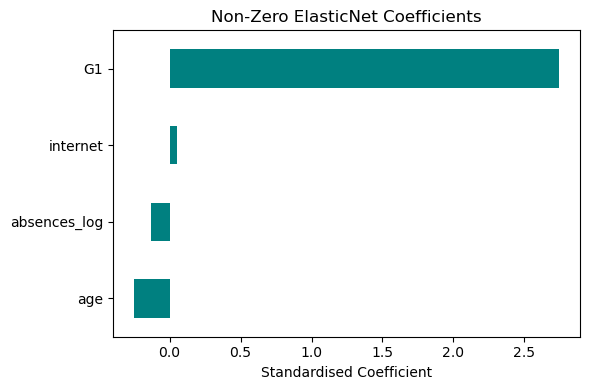

In [37]:
best_elasticnet = tuned_models_perf["ElasticNet"].best_estimator_

coefficients = pd.Series(
    best_elasticnet.named_steps["regression"].coef_,
    index=X_train_perf_G1_engineered.columns
)
coefficients = coefficients[coefficients != 0].sort_values(key=abs, ascending=False)

display(coefficients.to_frame("Standardised Coefficient"))

plt.figure(figsize=(6, 4))
coefficients.sort_values().plot(kind="barh", color="teal")
plt.title("Non-Zero ElasticNet Coefficients")
plt.xlabel("Standardised Coefficient")
plt.tight_layout()
plt.show()

Following regularisation, ElasticNet retains only four features with non-zero coefficients.

G1 has by far the largest positive coefficient, reinforcing its dominant role in predicting final grades. Age and log-transformed absences have smaller negative coefficients, whilst internet access has a small positive coefficient.

The remaining socio-environmental and engineered features are assigned coefficients of zero, suggesting that they provide limited additional predictive information within this fitted model.

### Prediction Error Analysis

Whilst ElasticNet achieves the best overall cross-validated performance, aggregate metrics may conceal differences in predictive accuracy across students.

Predicted grades and residuals are plotted for both ElasticNet and the G1 persistence baseline using out-of-fold predictions from the training data. This allows their performance to be compared across the full grade distribution and helps to identify any systematic patterns in prediction errors.

Residuals are calculated as predicted minus actual grades, such that positive values indicate overprediction and negative values indicate underprediction. The residuals are plotted against actual grades to examine how the models perform across the full attainment spectrum.

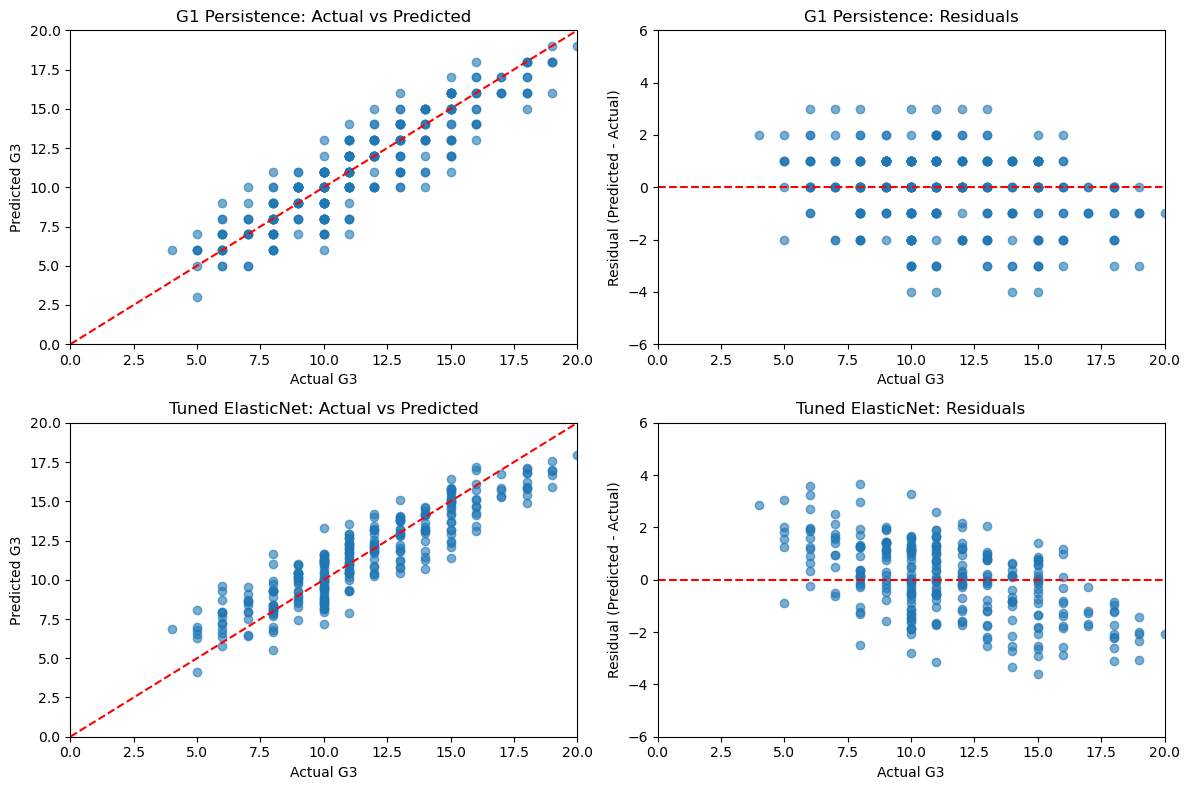

In [38]:
train_cv_preds = cross_val_predict(
    tuned_models_perf["ElasticNet"], X_train_perf_G1_engineered, y_train_perf, cv=cv_perf
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

models = [
    ("G1 Persistence", g1_train),
    ("Tuned ElasticNet", train_cv_preds)
]

for i, (name, preds) in enumerate(models):

    residuals = np.asarray(preds) - y_train_perf.to_numpy()

    axes[i, 0].scatter(y_train_perf, preds, alpha=0.6)
    axes[i, 0].plot([0, 20], [0, 20], "r--")
    axes[i, 0].set_xlabel("Actual G3")
    axes[i, 0].set_ylabel("Predicted G3")
    axes[i, 0].set_title(f"{name}: Actual vs Predicted")
    axes[i, 0].set_xlim(0, 20)
    axes[i, 0].set_ylim(0, 20)

    axes[i, 1].scatter(y_train_perf, residuals, alpha=0.6)
    axes[i, 1].axhline(0, color="red", linestyle="--")
    axes[i, 1].set_xlabel("Actual G3")
    axes[i, 1].set_ylabel("Residual (Predicted - Actual)")
    axes[i, 1].set_title(f"{name}: Residuals")
    axes[i, 1].set_xlim(0, 20)
    axes[i, 1].set_ylim(-6, 6)

plt.tight_layout()
plt.show()

At first glance, ElasticNet appears to produce more tightly clustered predictions than the G1 persistence baseline, suggesting a reduction in the overall spread of prediction errors. However, closer inspection reveals a more pronounced systematic pattern.

Both models show a tendency to overpredict lower grades and underpredict higher grades, but this effect is considerably stronger for ElasticNet. Its predictions are more concentrated towards the centre of the grade distribution, consistent with a regression-to-the-mean effect in which extreme grades are pulled towards more moderate values.

To investigate this further, prediction errors for both models are examined across three final-grade bands: low (G3 ≤ 8), middle (9–15) and high (16–20). Mean residuals and MAE are calculated for each band to assess both the direction and magnitude of prediction errors across the grade distribution.

In [39]:
comparison_results_perf = []
band_results_perf = []

models = [
    ("G1 Persistence", g1_train),
    ("Tuned ElasticNet", train_cv_preds)
]

for name, preds in models:
    metrics = evaluate_performance_model(name, y_train_perf, preds)
    comparison_results_perf.append(metrics)

    errors = pd.DataFrame({
        "Actual": y_train_perf.to_numpy(),
        "Residual": preds - y_train_perf.to_numpy()
    })
    errors["Grade Band"] = pd.cut(
        errors["Actual"], bins=[0, 8, 15, 20], labels=["Low", "Middle", "High"]
    )

    for band, group in errors.groupby("Grade Band", observed=True):
        band_results_perf.append({
            "Model": name,
            "Grade Band": band,
            "Count": len(group),
            "Mean Residual": group["Residual"].mean(),
            "MAE": group["Residual"].abs().mean()
        })

display(pd.DataFrame(comparison_results_perf))
display(pd.DataFrame(band_results_perf).round(2))

,Model,MAE,RMSE,R²
0,G1 Persistence,1.16,1.50,0.80
1,Tuned ElasticNet,1.15,1.42,0.82


,Model,Grade Band,Count,Mean Residual,MAE
0,G1 Persistence,Low,56,0.29,1.07
1,G1 Persistence,Middle,199,-0.21,1.20
2,G1 Persistence,High,33,-0.85,1.09
3,Tuned ElasticNet,Low,56,1.03,1.35
4,Tuned ElasticNet,Middle,199,-0.05,1.02
5,Tuned ElasticNet,High,33,-1.48,1.61


The grade-band analysis reinforces the patterns observed in the prediction error plots. Whilst ElasticNet achieves slightly better overall performance, improvements are not consistent across the grade distribution.

ElasticNet performs better for middle-attaining students, reducing MAE from 1.20 to 1.02. However, its performance deteriorates at both extremes, with MAE increasing from 1.07 to 1.35 for low attainers and from 1.09 to 1.61 for high attainers. The mean residuals also confirm a stronger tendency to overpredict low grades (+1.03) and underpredict high grades (−1.48), consistent with predictions being pulled towards the centre of the grade distribution.

These findings suggest that ElasticNet's narrower range of predictions reduces the magnitude of some errors, particularly among middle-attaining students, but introduces greater systematic bias at the extremes. Given the project's focus on identifying students experiencing academic difficulties, its reduced accuracy among low attainers is particularly concerning. The marginal improvement in overall performance therefore does not necessarily make ElasticNet preferable to the simpler G1 persistence baseline.

### Model Selection and Test-Set Evaluation

Further experiments involving tree-based models, polynomial features and alternative weighting strategies did not produce meaningful improvements in predictive performance or resolve the systematic errors observed at the extremes of the grade distribution.

Overall, ElasticNet achieves the best aggregate cross-validated performance, but its improvement over G1 persistence is marginal and comes at the expense of reduced accuracy among low and high-attaining students.

Both approaches are therefore retained for final evaluation on the withheld test set, to assess how they generalise to unseen data. 

In [40]:
final_elasticnet = tuned_models_perf["ElasticNet"]

final_elasticnet.fit(X_train_perf_G1_engineered, y_train_perf)

elasticnet_test_preds = final_elasticnet.predict(X_test_perf_G1_engineered)

g1_test_preds = df.loc[y_test_perf.index, "G1"].to_numpy()

### Test Results

Both models are fitted on the full training data and evaluated on the withheld test data, following a similar procedure to that used for the cross-validated training predictions.

,Model,MAE,RMSE,R²
0,G1 Persistence,1.22,1.61,0.70
1,Tuned ElasticNet,1.18,1.47,0.75


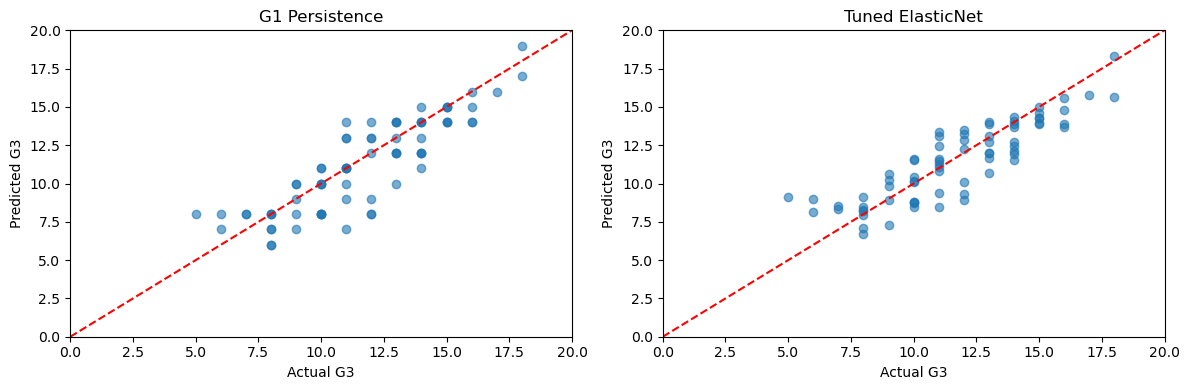

In [41]:
test_results_perf = []

models = [
    ("G1 Persistence", g1_test_preds),
    ("Tuned ElasticNet", elasticnet_test_preds)
]

for name, preds in models:
    test_results_perf.append(
        evaluate_performance_model(name, y_test_perf, preds)
    )

display(pd.DataFrame(test_results_perf))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, (name, preds) in enumerate(models):
    axes[i].scatter(y_test_perf, preds, alpha=0.6)
    axes[i].plot([0, 20], [0, 20], "r--")
    axes[i].set_xlabel("Actual G3")
    axes[i].set_ylabel("Predicted G3")
    axes[i].set_title(name)
    axes[i].set_xlim(0, 20)
    axes[i].set_ylim(0, 20)

plt.tight_layout()
plt.show()

ElasticNet maintains its slight advantage over G1 persistence on the withheld test data, out-performing the baseline model across all three metrics. This suggests that the improvements observed during cross-validation generalise to unseen data.

However, the scatterplots reveal similar patterns to those observed during training. ElasticNet produces a narrower range of predictions, with a tendency to overpredict lower grades and underpredict higher grades. Despite its improved overall accuracy, the systematic errors at the extremes of the grade distribution remain a significant limitation, particularly when predicting outcomes for low-attaining students.

In [42]:
test_band_results_perf = []

for name, preds in models:

    errors = pd.DataFrame({
        "Actual": y_test_perf.to_numpy(),
        "Residual": np.asarray(preds) - y_test_perf.to_numpy()
    })

    errors["Grade Band"] = pd.cut(
        errors["Actual"],
        bins=[0, 8, 15, 20],
        labels=["Low", "Middle", "High"]
    )

    for band, group in errors.groupby("Grade Band", observed=True):
        test_band_results_perf.append({
            "Model": name,
            "Grade Band": band,
            "Count": len(group),
            "Mean Residual": group["Residual"].mean(),
            "MAE": group["Residual"].abs().mean()
        })

display(pd.DataFrame(test_band_results_perf).round(2))

,Model,Grade Band,Count,Mean Residual,MAE
0,G1 Persistence,Low,12,0.17,1.17
1,G1 Persistence,Middle,54,-0.54,1.24
2,G1 Persistence,High,7,-0.86,1.14
3,Tuned ElasticNet,Low,12,0.99,1.38
4,Tuned ElasticNet,Middle,54,-0.32,1.10
5,Tuned ElasticNet,High,7,-1.33,1.42


The test-set grade-band results reproduce the same systematic patterns observed during cross-validation. Whilst Elasticnet outperforms G1 persistence for middle-band students, it performs considerably worse at both extremes, overpredicting low-band students are underpredicting high-band students.

## Regression Model Summary

ElasticNet achieves the best overall predictive performance, marginally outperforming G1 persistence during cross-validation and on the held-out test set. However, when considering its reduced accuracy for low-attaining students, combined with only modest improvements in overall performance, the additional model complexity does not appear justifiable.

In general, the magnitude of individual prediction errors and the systematic biases observed across the grade distribution limit the practical usefulness of both models for predicting individual final grades.

The practical objective of this notebook is to identify students who may benefit from additional academic support. Rather than attempting to predict exact final grades, a more pragmatic approach may be to identify students at risk of low attainment. This reframes the task as a binary classification problem, distinguishing students likely to achieve G3 ≤ 8 from those expected to perform above this threshold.

As an initial investigation, the existing ElasticNet and G1 persistence models are evaluated as intervention screening tools, flagging students whose predicted final grades are G3 ≤ 8. This provides a baseline for assessing whether dedicated classification models can offer a more effective approach to intervention selection.

In [43]:
from sklearn.metrics import precision_score, recall_score, f1_score

low_grade_results = []

actual_low = (y_train_perf <= 8).astype(int)

models = [
    ("G1 Persistence", g1_train),
    ("Tuned ElasticNet", train_cv_preds)
]

for name, preds in models:
    predicted_low = (np.asarray(preds) <= 8).astype(int)

    low_grade_results.append({
        "Model": name,
        "Flagged": predicted_low.sum(),
        "Precision": precision_score(actual_low, predicted_low, zero_division=0),
        "Recall": recall_score(actual_low, predicted_low, zero_division=0),
        "F1": f1_score(actual_low, predicted_low, zero_division=0)
    })

display(pd.DataFrame(low_grade_results).round(2))

,Model,Flagged,Precision,Recall,F1
0,G1 Persistence,67,0.67,0.8,0.73
1,Tuned ElasticNet,32,0.88,0.5,0.64


ElasticNet achieves higher precision than G1 persistence, but at the expense of significantly lower recall. Whilst its predictions are more selective, this results in a greater proportion of low-performing students being missed.

Preferences in precision-recall balance may vary depending on the availability of intervention resources. Where resources are limited, ElasticNet would be preferable as it identifies a smaller group of students with greater precision. Conversely, where more support is available, G1 persistence may be more suitable due to its higher recall.

However, both approaches involve a trade-off between identifying students in need of support and avoiding unnecessary interventions. Dedicated classification models are therefore investigated to determine whether directly predicting low attainment can further improve intervention flagging beyond these regression-based approaches.

## Low-Performance Classifiers

Three classification models are investigated: Logistic Regression, Random Forest and XGBoost. These models are trained to identify students at risk of achieving G3 ≤ 8, with the aim of improving intervention flagging beyond the G1 persistence baseline.

The same train-test split used for regression is retained, along with the engineered features, allowing for a consistent comparison between approaches.

In [44]:
X_train_low = X_train_perf_G1_engineered
y_train_low = (y_train_perf <= 8).astype(int)

print("Students achieving G3 <= 8:", y_train_low.sum())
print("Proportion:", round(y_train_low.mean(), 3))

Students achieving G3 <= 8: 56
Proportion: 0.194


### Hyperparameter Tuning and Initial Model Evaluation

Within the training set, 56 students (19.4%) fall into the low-attainment category.

Models are optimised using GridSearchCV, with Average Precision as the selection metric to account for the imbalance between low-attaining and other students. Nested cross-validation is then used to generate out-of-fold predicted probabilities, allowing performance to be evaluated without using the withheld test set.


The tuned classifiers are then compared against the G1 ≤ 8 baseline using precision, recall, F1, ROC-AUC and Average Precision.

A default probability threshold of 0.5 is used to classify students as at risk. This provides a starting point for comparing the models before investigating whether adjusting the classification threshold can produce a more suitable balance between precision and recall.

In [45]:
param_log_low = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"],
    "class_weight": [None, "balanced"]
}

param_rf_low = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, None],
    "min_samples_leaf": [2, 5],
    "class_weight": [None, "balanced"]
}

param_xgb_low = {
    "n_estimators": [100, 200],
    "max_depth": [2, 3],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.8, 1.0]
}

models_to_tune_low = [
    ("Logistic Regression",
     LogisticRegression(max_iter=2000, random_state=42),
     param_log_low),

    ("Random Forest",
     RandomForestClassifier(random_state=42, n_jobs=1),
     param_rf_low),

    ("XGBoost",
     XGBClassifier(
         objective="binary:logistic",
         eval_metric="logloss",
         random_state=42,
         n_jobs=1
     ),
     param_xgb_low)
]

low_grade_results = []
low_grade_probs = {}
low_grade_best_models = {}

g1_low_preds = (np.asarray(g1_train) <= 8).astype(int)
g1_low_scores = -np.asarray(g1_train)

low_grade_results.append({
    "Model": "G1 <= 8 Baseline",
    "Precision": precision_score(y_train_low, g1_low_preds),
    "Recall": recall_score(y_train_low, g1_low_preds),
    "F1": f1_score(y_train_low, g1_low_preds),
    "ROC-AUC": roc_auc_score(y_train_low, g1_low_scores),
    "Average Precision": average_precision_score(y_train_low, g1_low_scores)
})

def tune_low_grade_model(name, model, params):

    search = GridSearchCV(
        model,
        params,
        cv=cv_perf,
        scoring="average_precision",
        n_jobs=-1
    )

    cv_probs = cross_val_predict(
        search,
        X_train_low,
        y_train_low,
        cv=cv_perf,
        method="predict_proba"
    )[:, 1]

    cv_preds = (cv_probs >= 0.5).astype(int)

    low_grade_results.append({
        "Model": name,
        "Precision": precision_score(y_train_low, cv_preds),
        "Recall": recall_score(y_train_low, cv_preds),
        "F1": f1_score(y_train_low, cv_preds),
        "ROC-AUC": roc_auc_score(y_train_low, cv_probs),
        "Average Precision": average_precision_score(y_train_low, cv_probs)
    })

    low_grade_probs[name] = cv_probs

    search.fit(X_train_low, y_train_low)
    low_grade_best_models[name] = search.best_estimator_

for name, model, params in models_to_tune_low:
    tune_low_grade_model(name, model, params)

display(pd.DataFrame(low_grade_results).round(2))


,Model,Precision,Recall,F1,ROC-AUC,Average Precision
0,G1 <= 8 Baseline,0.67,0.80,0.73,0.95,0.78
1,Logistic Regression,0.71,0.09,0.16,0.91,0.68
2,Random Forest,0.72,0.38,0.49,0.90,0.67
3,XGBoost,0.69,0.62,0.65,0.92,0.78


At the default classification threshold of 0.5, none of the classifiers outperform the G1 persistence baseline. Logistic Regression and Random Forest achieve slightly higher precision, but their recall is significantly lower (0.09 and 0.38, respectively). XGBoost performs better, but remains inferior to the baseline.

However, the strong ROC-AUC scores (0.90–0.92) suggest that the classifiers can distinguish between low-attaining and other students, even if the default threshold produces poor results.

Lower classification thresholds are therefore investigated to determine whether recall can be improved whilst maintaining sufficient precision for practical application.

In [46]:
threshold_results = []

for name, probs in low_grade_probs.items():

    for threshold in [0.2, 0.25, 0.3, 0.35, 0.4]:

        preds = (probs >= threshold).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Flagged": preds.sum(),
            "Precision": precision_score(y_train_low, preds),
            "Recall": recall_score(y_train_low, preds),
            "F1": f1_score(y_train_low, preds)
        })

display(pd.DataFrame(threshold_results).round(2))

,Model,Threshold,Flagged,Precision,Recall,F1
0,Logistic Regression,0.20,147,0.37,0.96,0.53
1,Logistic Regression,0.25,89,0.57,0.91,0.70
2,Logistic Regression,0.30,66,0.65,0.77,0.70
3,Logistic Regression,0.35,30,0.70,0.38,0.49
4,Logistic Regression,0.40,17,0.65,0.20,0.30
5,Random Forest,0.20,115,0.45,0.93,0.61
6,Random Forest,0.25,92,0.54,0.89,0.68
7,Random Forest,0.30,79,0.61,0.86,0.71
8,Random Forest,0.35,68,0.62,0.75,0.68
9,Random Forest,0.40,56,0.66,0.66,0.66


Lowering the classification threshold improves recall across all three models, however this comes at the expense of precision and an increase in the number of students flagged.

All three models demonstrate competitive performance at certain thresholds. Random Forest (0.30) and Logistic Regression (0.25) are selected for further evaluation alongside G1 persistence.

Their performance is compared using cross-validated training predictions, with precision, recall, F1 and confusion matrices used to assess their suitability for intervention screening.

,Model,Flagged,Precision,Recall,F1
0,G1 Persistence,67,0.67,0.80,0.73
1,Random Forest (0.3),79,0.61,0.86,0.71
2,Logistic Regression (0.25),89,0.57,0.91,0.70


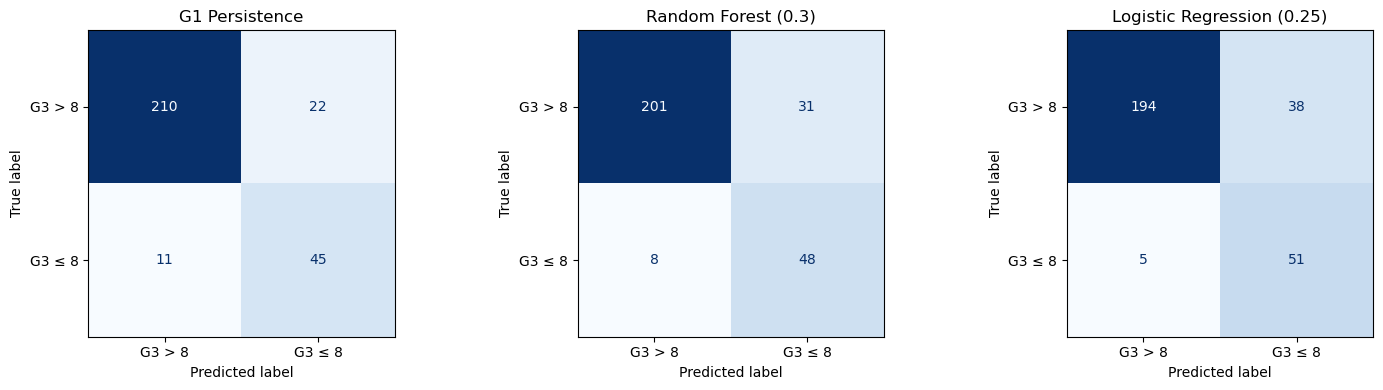

In [47]:
rf_low_preds = (low_grade_probs["Random Forest"] >= 0.3).astype(int)
lr_low_preds = (low_grade_probs["Logistic Regression"] >= 0.25).astype(int)

models = [
    ("G1 Persistence", g1_low_preds),
    ("Random Forest (0.3)", rf_low_preds),
    ("Logistic Regression (0.25)", lr_low_preds)
]

comparison_low = []

for name, preds in models:
    comparison_low.append({
        "Model": name,
        "Flagged": preds.sum(),
        "Precision": precision_score(y_train_low, preds),
        "Recall": recall_score(y_train_low, preds),
        "F1": f1_score(y_train_low, preds)
    })

display(pd.DataFrame(comparison_low).round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, preds) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_train_low,
        preds,
        ax=ax,
        colorbar=False,
        cmap="Blues",
        display_labels=["G3 > 8", "G3 ≤ 8"]
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

Both classifiers achieve higher recall than G1 persistence, but at the cost of worse precision. The results suggest diminishing returns, with each additional successfully flagged student requiring a disproportionate increase in unnecessary flags. Where resources are limited, these small gains in recall may therefore be difficult to justify.

Ultimately, neither classifier improves upon the baseline's F1 score of 0.73, suggesting that the additional complexity offers no clear overall advantage. Nevertheless, their higher recall may be valuable where intervention resources are more readily available and recall is prioritised.

### Test-Set Evaluation

The selected Random Forest and Logistic Regression classifiers are finally evaluated on the held-out test set using their previously chosen thresholds of 0.30 and 0.25, respectively. Their performance is compared against G1 persistence to assess how well the cross-validation results generalise to unseen data.

,Model,Flagged,Precision,Recall,F1
0,G1 Persistence,21,0.57,1.00,0.73
1,Random Forest (0.3),17,0.53,0.75,0.62
2,Logistic Regression (0.25),24,0.50,1.00,0.67


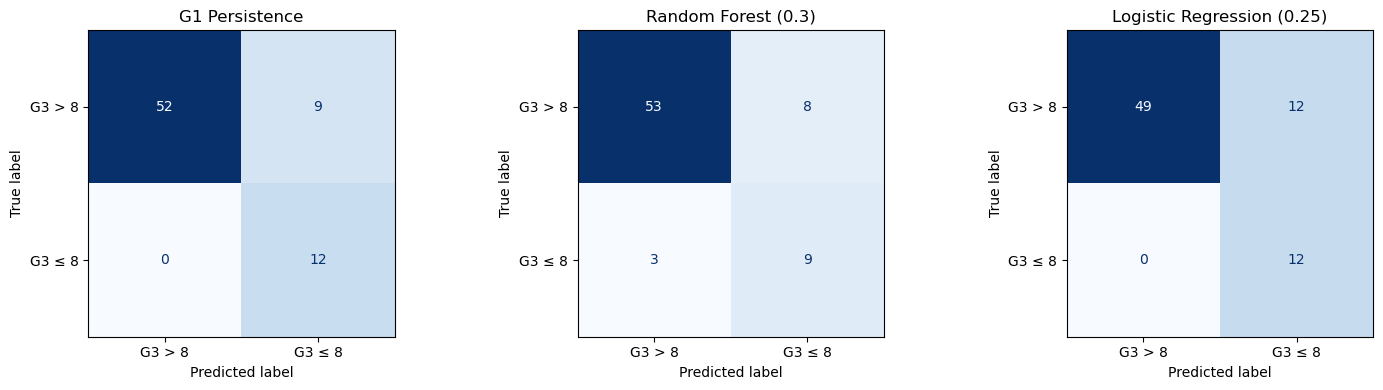

In [48]:
X_test_low = X_test_perf_G1_engineered
y_test_low = (y_test_perf <= 8).astype(int)

rf_low_test_probs = low_grade_best_models["Random Forest"].predict_proba(X_test_low)[:, 1]
lr_low_test_probs = low_grade_best_models["Logistic Regression"].predict_proba(X_test_low)[:, 1]

rf_low_test_preds = (rf_low_test_probs >= 0.3).astype(int)
lr_low_test_preds = (lr_low_test_probs >= 0.25).astype(int)

g1_low_test_preds = (np.asarray(g1_test_preds) <= 8).astype(int)

models_test = [
    ("G1 Persistence", g1_low_test_preds),
    ("Random Forest (0.3)", rf_low_test_preds),
    ("Logistic Regression (0.25)", lr_low_test_preds)
]

comparison_low_test = []

for name, preds in models_test:
    comparison_low_test.append({
        "Model": name,
        "Flagged": preds.sum(),
        "Precision": precision_score(y_test_low, preds),
        "Recall": recall_score(y_test_low, preds),
        "F1": f1_score(y_test_low, preds)
    })

display(pd.DataFrame(comparison_low_test).round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, preds) in zip(axes, models_test):
    ConfusionMatrixDisplay.from_predictions(
        y_test_low,
        preds,
        ax=ax,
        colorbar=False,
        cmap="Blues",
        display_labels=["G3 > 8", "G3 ≤ 8"]
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

On the withheld test set, G1 persistence achieves the best overall performance, with Logistic Regression remaining competitive and Random Forest performing slightly worse. However, the relatively small test set limits the reliability of these comparisons.

In conclusion, there is insufficient evidence that dedicated classification models offer a meaningful improvement over G1 persistence, and as such, their additional complexity cannot be justified at this stage. Given its simplicity, strong predictive performance and ease of implementation, G1 persistence is therefore recommended as the preferred practical approach for intervention screening.

## Modelling Summary and Discussion

The practical objective of this project is to identify students at risk of poor academic outcomes, with the aim of supporting early intervention. Across both modelling tasks, **first-period grades (G1) emerge as the dominant predictor**, highlighting the importance of early academic performance in identifying students who may require additional support.

Socio-environmental features provide some useful predictive information, particularly for non-completion risk, but their contribution to final-grade prediction is limited once G1 is included. Feature engineering and more sophisticated modelling techniques offer limited improvements, suggesting that most of the available predictive information is already captured by early academic performance.

For final-grade prediction, ElasticNet achieves the best overall accuracy but offers only marginal improvements over trivial G1 persistence, alongside greater systematic errors for low-attaining students. Dedicated low-attainment classifiers also fail to demonstrate a meaningful advantage over the simple G1 ≤ 8 classifier. Given its simplicity and surprisingly strong performance, G1 persistence classification (G1 ≤ 8) is decided as the most practical approach to identifying students at risk of low attainment.

The non-completion risk model, however, provides a potentially useful additional perspective. The final Logistic Regression model demonstrates promising discriminatory performance, achieving a test ROC-AUC of 0.88. Whilst its precision and recall remain imperfect, it may help distinguish students at greater risk of non-completion, beyond simply identifying those with low grades.

### Limitations

The limited size of the dataset may partly explain why more complex models offer little improvement over simple G1 baselines, particularly given the small number of non-completers and low-attaining students. However, the available features may also be a limiting factor; it may simply be that the available socio-environmental characteristics offer little additional predictive value beyond what is already captured by G1, given its strong relationship with final academic outcomes. A more comprehensive set of features might better capture students' academic circumstances and potentially improve predictions.

There are also limitations to the definition of non-completion, which is inferred from G3 = 0 rather than confirmed withdrawal records. Some cases may therefore reflect circumstances unrelated to academic difficulties. Consequently, whilst the results provide a useful basis for developing an intervention strategy, further validation using larger datasets and more comprehensive student records would be necessary before practical implementation.

### Proposed Intervention Framework

Given these findings, a simple intervention prioritisation framework is proposed, combining the **G1 persistence classifier (G1 ≤ 8)** with the **non-completion risk classifier**. Both models could be utilised, and students assigned to three priority groups according to the number of risk indicators triggered:

- **High priority:** Both models flag the student.
- **Moderate priority:** One model flags the student.
- **Low priority:** Neither model flags the student.

This approach would retain the simplicity and strong screening performance of G1 persistence whilst incorporating the additional information captured by the non-completion model. Rather than attempting to predict exact academic outcomes, it would provide an interpretable means of prioritising students for further assessment and support.

The potential value of this framework could be investigated by examining how effectively the resulting priority groups distinguish students experiencing poor academic outcomes, and whether combining the two indicators offers a meaningful improvement over G1 alone.